# Microsoft: cash generation, capital spending and refinancing capacity
**Research question:** Does growing infrastructure investment materially weaken internally funded debt-service capacity?

A historical issuer-credit case study using Microsoft FY2023–FY2025 financial statements and the debt maturity schedule at 30 June 2025. The financial statements are actual disclosures; stress scenarios are analyst assumptions. This is not a current credit rating or bond trade recommendation.

## Source and accounting choices
All input amounts below are USD millions, transcribed from [Microsoft's FY2025 annual report](https://www.microsoft.com/investor/reports/ar25/), retrieved 30 October 2026. Source sections: Income Statements; Cash Flows Statements; Note 3 Other Income (Expense), Net; Note 10 Debt. The report supplies three-year income and cash-flow comparatives.

Use **operating income**, not an invented EBITDA measure. FCF is defined here as operating cash flow less cash additions to property and equipment; it excludes acquisitions and does not capture noncash finance-lease additions. Net-debt-to-EBITDA and default probabilities are deliberately not inferred from incomplete inputs.

Run all cells in Colab/Jupyter; numpy, pandas, matplotlib required. No downloads or local data files needed. This frozen FY2025 case is not presented as the latest filing. Review and extend the assisted analysis before citing it as your research.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO
from pathlib import Path
try:
    display
except NameError:
    def display(x): print(x)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .2})
pd.set_option('display.max_columns', 15)
OUT = Path('research_outputs'); OUT.mkdir(exist_ok=True)

In [2]:
financials=pd.DataFrame({
 'FY':[2023,2024,2025],
 'revenue':[211915,245122,281724],
 'operating_income':[88523,109433,128528],
 'interest_expense':[1968,2935,2385],
 'operating_cash_flow':[87582,118548,136162],
 'cash_capex':[28107,44477,64551],
 'cash_dividends':[19800,21771,24082],
 'cash_repurchases':[22245,17254,18420]
}).set_index('FY')
maturities=pd.Series({'FY2026':3000,'FY2027':9250,'FY2028':0,'FY2029':2054,'FY2030':0,'Thereafter':34902},name='Principal USD million')
# Note 10: reconcile contractual principal to carrying amount (not an invented market price).
reconciliation=pd.Series({'Face value':49206,'Unamortized discount and issuance costs':-1155,'Hedge fair value adjustments':-36,'Premium on debt exchange':-4864})
carrying_amount=43151
assert maturities.sum()==49206 and reconciliation.sum()==carrying_amount
assert (financials>0).all().all()
display(financials);display(maturities.to_frame());display(reconciliation.to_frame())

,revenue,operating_income,interest_expense,operating_cash_flow,cash_capex,cash_dividends,cash_repurchases
FY,,,,,,,
2023,211915,88523,1968,87582,28107,19800,22245
2024,245122,109433,2935,118548,44477,21771,17254
2025,281724,128528,2385,136162,64551,24082,18420


,Principal USD million
FY2026,3000
FY2027,9250
FY2028,0
FY2029,2054
FY2030,0
Thereafter,34902


,0
Face value,49206
Unamortized discount and issuance costs,-1155
Hedge fair value adjustments,-36
Premium on debt exchange,-4864


,revenue,operating_income,interest_expense,operating_cash_flow,cash_capex,cash_dividends,cash_repurchases,FCF,FCF_margin,capex_to_CFO,EBIT_interest_coverage,FCF_after_distributions,revenue_growth
FY,,,,,,,,,,,,,
2023,211915,88523,1968,87582,28107,19800,22245,59475,0.2807,0.3209,44.9812,17430,NaN
2024,245122,109433,2935,118548,44477,21771,17254,74071,0.3022,0.3752,37.2855,35046,0.1567
2025,281724,128528,2385,136162,64551,24082,18420,71611,0.2542,0.4741,53.8901,29109,0.1493


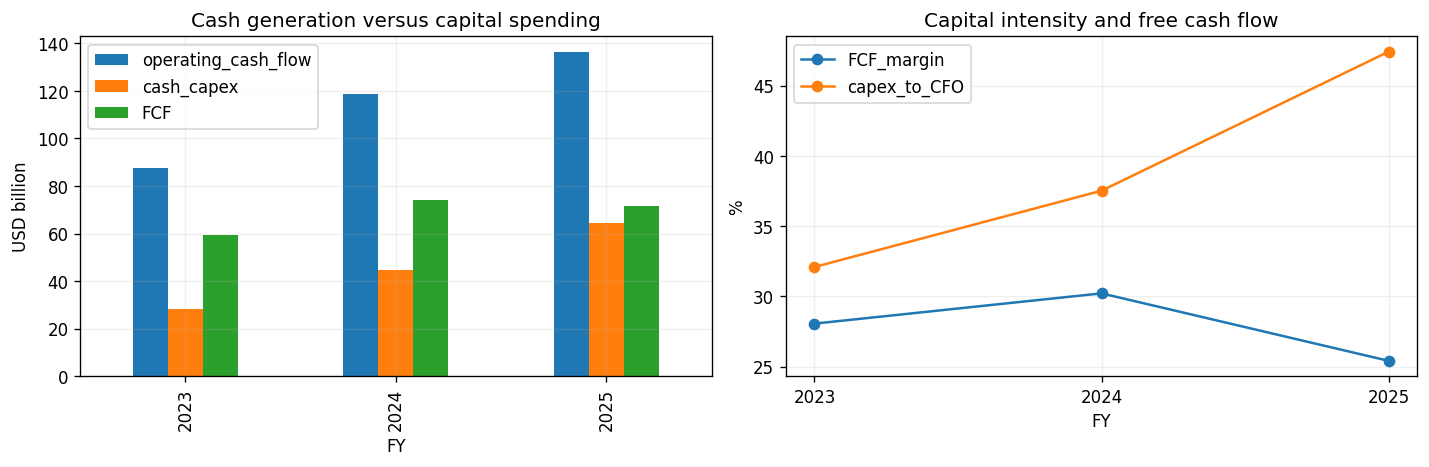

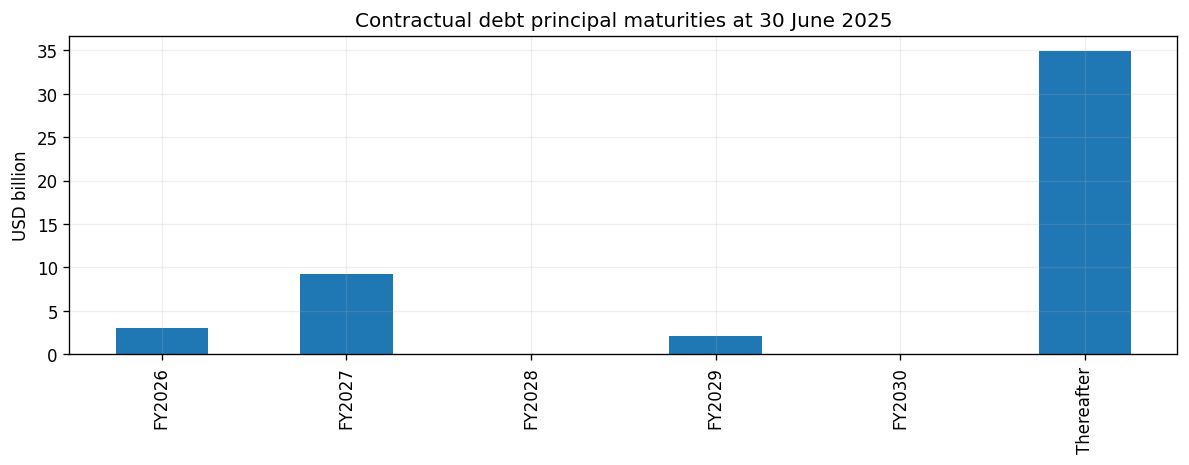

In [3]:
ratios=financials.copy()
ratios['FCF']=ratios.operating_cash_flow-ratios.cash_capex
ratios['FCF_margin']=ratios.FCF/ratios.revenue
ratios['capex_to_CFO']=ratios.cash_capex/ratios.operating_cash_flow
ratios['EBIT_interest_coverage']=ratios.operating_income/ratios.interest_expense
ratios['FCF_after_distributions']=ratios.FCF-ratios.cash_dividends-ratios.cash_repurchases
ratios['revenue_growth']=ratios.revenue.pct_change()
display(ratios.round(4));ratios.to_csv(OUT/'microsoft_credit_ratios.csv')
fig,ax=plt.subplots(1,2,figsize=(12,4))
(ratios[['operating_cash_flow','cash_capex','FCF']]/1000).plot.bar(ax=ax[0],title='Cash generation versus capital spending');ax[0].set_ylabel('USD billion')
(ratios[['FCF_margin','capex_to_CFO']]*100).plot(marker='o',ax=ax[1],title='Capital intensity and free cash flow');ax[1].set_ylabel('%');ax[1].set_xticks(ratios.index)
plt.tight_layout();plt.show()
(maturities/1000).plot.bar(title='Contractual debt principal maturities at 30 June 2025',ylabel='USD billion');plt.tight_layout();plt.show()

## Stress design — assumptions, not management forecasts
Hold FY2025 dividends and buybacks constant to make discretionary distributions visible. Stress CFO down 0–40% and cash capex up 0–30%. Add a 200 bp refinancing-rate shock on FY2026 principal ($3,000m), assumed outstanding for a full year: incremental cash interest $60m. No tax shield is assumed. The cash-flow stress and incremental interest are distinct shocks.

Subtract FY2026 principal in the no-rollover liquidity case. Compare with a rollover case that excludes repayment. These are single-year bridges, not a full financial forecast: working capital, taxes, acquisitions, leases, commitments and opening liquidity are not separately projected. CFO already includes base cash interest, so only incremental interest is deducted.

PASS: debt reconciliation, FCF arithmetic, interest shock and monotonic stress response
FY2025 FCF: $71.61bn; FCF margin 25.42%.
FY2025 capex/CFO: 47.41%, versus 32.09% in FY2023.
With unchanged capex and distributions, this bridge reaches zero after a 19.13% CFO decline.


capex_increase,0.0,0.1,0.2,0.3
CFO_decline,,,,
0.0,26.05,19.59,13.14,6.68
0.1,12.43,5.98,-0.48,-6.93
0.2,-1.18,-7.64,-14.09,-20.55
0.3,-14.80,-21.25,-27.71,-34.16
0.4,-28.42,-34.87,-41.33,-47.78


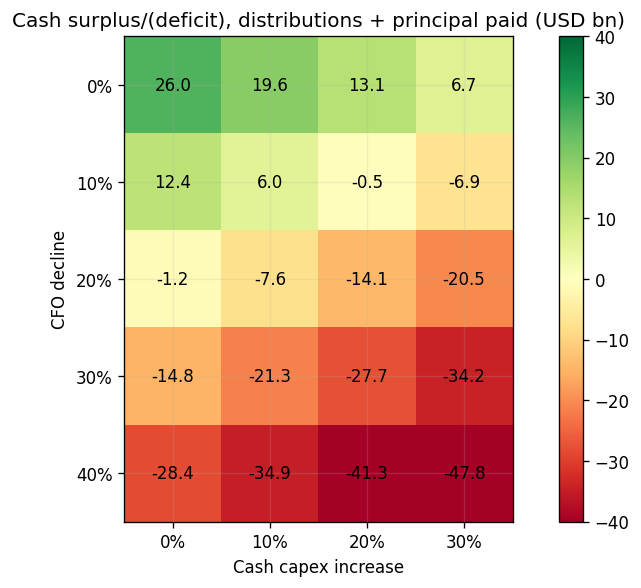

In [4]:
base=ratios.loc[2025];principal=float(maturities.loc['FY2026']);extra_interest=principal*.02
rows=[]
for cfo_drop in [0,.1,.2,.3,.4]:
    for capex_rise in [0,.1,.2,.3]:
        cfo=base.operating_cash_flow*(1-cfo_drop)
        capex=base.cash_capex*(1+capex_rise)
        fcf=cfo-capex-extra_interest
        after_div=fcf-base.cash_dividends
        after_all=after_div-base.cash_repurchases
        rows.append({'CFO_decline':cfo_drop,'capex_increase':capex_rise,'stressed_FCF':fcf,'after_dividends':after_div,'after_all_distributions_rollover':after_all,'after_distributions_and_principal':after_all-principal})
stress=pd.DataFrame(rows)
heat=stress.pivot(index='CFO_decline',columns='capex_increase',values='after_distributions_and_principal')/1000
display(heat.round(2));stress.to_csv(OUT/'microsoft_liquidity_stress.csv',index=False)
fig,ax=plt.subplots(figsize=(8,5));im=ax.imshow(heat,cmap='RdYlGn',vmin=-40,vmax=40)
ax.set_xticks(range(len(heat.columns)),[f'{v:.0%}' for v in heat.columns]);ax.set_yticks(range(len(heat.index)),[f'{v:.0%}' for v in heat.index])
for i in range(len(heat)):
    for j in range(len(heat.columns)):ax.text(j,i,f'{heat.iloc[i,j]:.1f}',ha='center',va='center')
ax.set(xlabel='Cash capex increase',ylabel='CFO decline',title='Cash surplus/(deficit), distributions + principal paid (USD bn)')
fig.colorbar(im,ax=ax);plt.tight_layout();plt.show()
assert abs(extra_interest-60)<1e-9
assert (np.diff(heat.to_numpy(),axis=0)<0).all() and (np.diff(heat.to_numpy(),axis=1)<0).all()
assert ratios.loc[2025,'FCF']==71611
breakeven=(base.operating_cash_flow-base.cash_capex-extra_interest-base.cash_dividends-base.cash_repurchases-principal)/base.operating_cash_flow
print('PASS: debt reconciliation, FCF arithmetic, interest shock and monotonic stress response')
print(f'FY2025 FCF: ${base.FCF/1000:.2f}bn; FCF margin {base.FCF_margin:.2%}.')
print(f'FY2025 capex/CFO: {base.capex_to_CFO:.2%}, versus {ratios.loc[2023,"capex_to_CFO"]:.2%} in FY2023.')
print(f'With unchanged capex and distributions, this bridge reaches zero after a {breakeven:.2%} CFO decline.')

## Credit interpretation and diligence priorities
Cash capex is taking a larger share of operating cash flow; revenue growth alone therefore overstates the improvement in discretionary cash generation. Read the stress table as a funding-gap indicator. A negative cell does not mean default: opening liquidity, capital-market access, reduced buybacks and investment flexibility can bridge it. A positive cell does not account for every contractual obligation.

The $9.25bn FY2027 principal maturity deserves separate multi-year planning. The long-term debt carrying amount differs from principal because of disclosed accounting adjustments; it must not be substituted for contractual repayments. Reported interest coverage also differs from debt-only cash-interest coverage and can be affected by interest capitalization.

Before recommending an actual bond: add cash/short-term investments, commercial paper, finance and operating lease liabilities, construction/purchase commitments, acquisitions and current issuer disclosures; obtain bond-specific executable prices, spreads, covenants, seniority and duration. This analysis supports an issuer discussion, not a relative-value conclusion without bond market data.